In [2]:
import sys
sys.path.append('..')

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_regression, SelectFromModel
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

from src.features.transformers import (
    CutOrdinalEncoder,
    DiamondFeatureGenerator,
    IsolationForestOutlierRemover
)

Path('../reports/png').mkdir(parents=True, exist_ok=True)

df = pd.read_csv('../data/raw/diamonds_fe.csv')
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_cols = ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut']
cat_cols = ['color', 'clarity']

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (43152, 10), Test shape: (10788, 10)


In [3]:
imputers = {
    'SimpleImputer (median)': SimpleImputer(strategy='median'),
    'KNNImputer (k=5)': KNNImputer(n_neighbors=5),
    'IterativeImputer (MICE)': IterativeImputer(max_iter=10, random_state=42)
}

imputation_results = []

for name, imputer in imputers.items():
    num_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('imputer', imputer)
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    preproc = ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols)
    ])
    pipe = Pipeline([
        ('cut_enc', CutOrdinalEncoder(column_name='cut')),
        ('preproc', preproc),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1))
    ])
    
    scores = cross_val_score(
        pipe, X_train, y_train,
        cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    mean_rmse = -scores.mean()
    std_rmse = scores.std()
    imputation_results.append({'Метод импутации': name, 'CV RMSE (mean)': round(mean_rmse, 2), 'CV RMSE (std)': round(std_rmse, 2)})
    print(f"{name}: RMSE = {mean_rmse:.2f} ± {std_rmse:.2f}")

imp_df = pd.DataFrame(imputation_results)
imp_df

SimpleImputer (median): RMSE = 592.17 ± 27.88
KNNImputer (k=5): RMSE = 587.81 ± 24.32
IterativeImputer (MICE): RMSE = 593.75 ± 24.52


,Метод импутации,CV RMSE (mean),CV RMSE (std)
0,SimpleImputer (median),592.17,27.88
1,KNNImputer (k=5),587.81,24.32
2,IterativeImputer (MICE),593.75,24.52


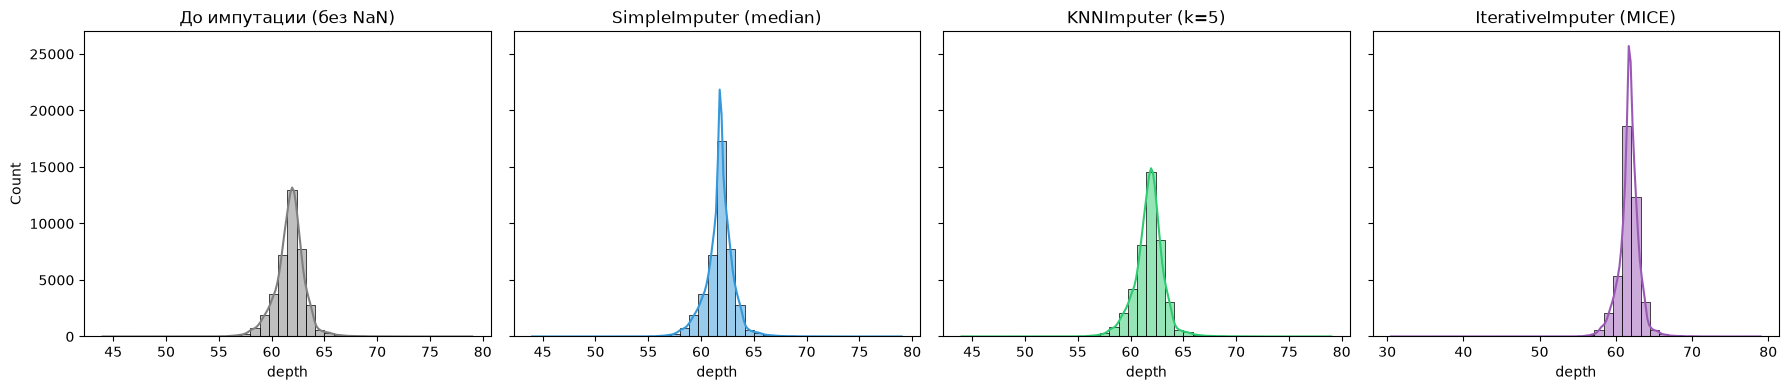

In [4]:
# Сравним распределение колонки 'depth' до и после заполнения
sample_num = X_train[['carat', 'depth', 'table', 'x', 'y', 'z']].copy()

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

sns.histplot(sample_num['depth'].dropna(), bins=40, kde=True, ax=axes[0], color='gray')
axes[0].set_title('До импутации (без NaN)')

colors = ['#3498db', '#2ecc71', '#9b59b6']
for idx, (name, imputer) in enumerate(imputers.items(), start=1):
    filled = imputer.fit_transform(sample_num)
    filled_depth = pd.Series(filled[:, 1], name='depth')
    sns.histplot(filled_depth, bins=40, kde=True, ax=axes[idx], color=colors[idx - 1])
    axes[idx].set_title(name)

plt.tight_layout()
plt.savefig('../reports/png/imputation_hist.png', dpi=150)
plt.show()

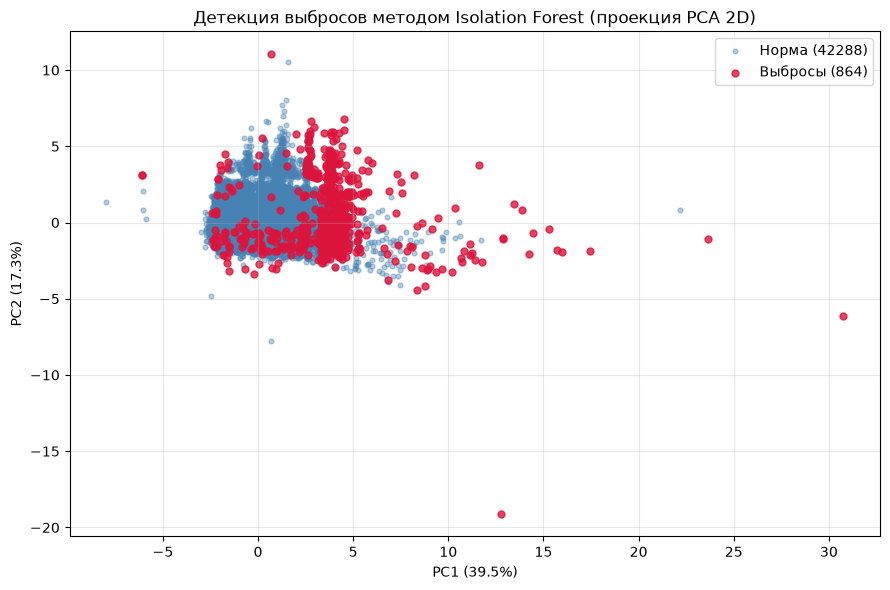

In [5]:
# Подготовим числовые данные для визуализации выбросов
X_train_cut = CutOrdinalEncoder('cut').fit_transform(X_train)
num_prep = Pipeline([
    ('imputer', IterativeImputer(max_iter=10, random_state=42)),
    ('scaler', StandardScaler())
])
X_num_scaled = num_prep.fit_transform(X_train_cut[num_cols])

iso = IsolationForest(contamination=0.02, random_state=42, n_jobs=-1)
outlier_Labels = iso.fit_predict(X_num_scaled)  # 1: норма, -1: выброс

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_num_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[outlier_Labels == 1, 0], X_pca[outlier_Labels == 1, 1],
    c='steelblue', alpha=0.4, s=12, label=f'Норма ({(outlier_Labels == 1).sum()})'
)
plt.scatter(
    X_pca[outlier_Labels == -1, 0], X_pca[outlier_Labels == -1, 1],
    c='crimson', alpha=0.8, s=25, label=f'Выбросы ({(outlier_Labels == -1).sum()})'
)
plt.title('Детекция выбросов методом Isolation Forest (проекция PCA 2D)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/png/outliers_pca.png', dpi=150)
plt.show()

In [6]:
base_preproc = ColumnTransformer([
    ('num', Pipeline([
        ('scaler', StandardScaler()),
        ('imputer', IterativeImputer(max_iter=10, random_state=42))
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

selection_configs = {
    '1. Без генерации и отбора (Baseline)': [
        ('cut_enc', CutOrdinalEncoder('cut')),
        ('preproc', base_preproc),
        ('outlier_rem', IsolationForestOutlierRemover(contamination=0.02, random_state=42)),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1))
    ],
    '2. С генерацией признаков (все признаки)': [
        ('cut_enc', CutOrdinalEncoder('cut')),
        ('preproc', base_preproc),
        ('outlier_rem', IsolationForestOutlierRemover(contamination=0.02, random_state=42)),
        ('feat_gen', DiamondFeatureGenerator()),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1))
    ],
    '3. Отбор: Mutual Information (SelectKBest k=15)': [
        ('cut_enc', CutOrdinalEncoder('cut')),
        ('preproc', base_preproc),
        ('outlier_rem', IsolationForestOutlierRemover(contamination=0.02, random_state=42)),
        ('feat_gen', DiamondFeatureGenerator()),
        ('select', SelectKBest(score_func=mutual_info_regression, k=15)),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1))
    ],
    '4. Отбор: Важности RandomForest (SelectFromModel)': [
        ('cut_enc', CutOrdinalEncoder('cut')),
        ('preproc', base_preproc),
        ('outlier_rem', IsolationForestOutlierRemover(contamination=0.02, random_state=42)),
        ('feat_gen', DiamondFeatureGenerator()),
        ('select', SelectFromModel(
            RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1),
            threshold='median'
        )),
        ('model', RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1))
    ]
}

sel_results = []
for label, steps in selection_configs.items():
    imb_pipe = ImbPipeline(steps)
    scores = cross_val_score(
        imb_pipe, X_train, y_train,
        cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    rmse_val = -scores.mean()
    sel_results.append({'Конфигурация пайплайна': label, 'CV RMSE': round(rmse_val, 2)})
    print(f"{label} -> CV RMSE: {rmse_val:.2f}")

pd.DataFrame(sel_results)

1. Без генерации и отбора (Baseline) -> CV RMSE: 644.93
2. С генерацией признаков (все признаки) -> CV RMSE: 644.41
3. Отбор: Mutual Information (SelectKBest k=15) -> CV RMSE: 972.22
4. Отбор: Важности RandomForest (SelectFromModel) -> CV RMSE: 709.57


,Конфигурация пайплайна,CV RMSE
0,1. Без генерации и отбора (Baseline),644.93
1,2. С генерацией признаков (все признаки),644.41
2,3. Отбор: Mutual Information (SelectKBest k=15),972.22
3,4. Отбор: Важности RandomForest (SelectFromModel),709.57


In [10]:
final_pipeline = ImbPipeline([
    ('cut_enc', CutOrdinalEncoder('cut')),
    ('preproc', base_preproc),
    ('outlier_rem', IsolationForestOutlierRemover(contamination=0.02, random_state=42)),
    ('feat_gen', DiamondFeatureGenerator()),
    ('select', SelectKBest(score_func=mutual_info_regression, k=18)),
    ('model', RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_split=5, random_state=42, n_jobs=-1))
])

final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== Итоговые метрики на отложенной тестовой выборке (Test) ===")
print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print(f"R^2:  {r2:.4f}")

joblib.dump(final_pipeline, '../models/pipeline_fe2.joblib', compress=3)

=== Итоговые метрики на отложенной тестовой выборке (Test) ===
RMSE: 841.97
MAE:  371.69
R^2:  0.9554


['../models/pipeline_fe2.joblib']